DISCRETE TRANSPORT PROBLEM
Number of bakeries N = 3
Number of cafes M = 4

SUPPLY AND DEMAND
-----------------------------------------------------------------
Bakery supplies = [5. 6. 4.]
Cafe demands = [3. 4. 5. 3.]
Total supply = 15.0
Total demand = 15.0

PASS: All supplies are positive.
PASS: All demands are positive.
PASS: Total supply equals total demand.
PASS: All locations are points in R^2.

EUCLIDEAN COST MATRIX
[[2.2361 5.3852 5.3852 7.8102]
 [5.3852 2.2361 6.4031 5.    ]
 [4.4721 4.4721 1.4142 3.1623]]

SQUARED EUCLIDEAN COST MATRIX
[[ 5. 29. 29. 61.]
 [29.  5. 41. 25.]
 [20. 20.  2. 10.]]

PASS: Squared Euclidean costs equal the square of Euclidean costs.

EUCLIDEAN COST TABLE
-----------------------------------------------------------------

          Cafe 1  Cafe 2  Cafe 3  Cafe 4
Bakery 1  2.2361  5.3852  5.3852  7.8102
Bakery 2  5.3852  2.2361  6.4031  5.0000
Bakery 3  4.4721  4.4721  1.4142  3.1623

SQUARED EUCLIDEAN COST TABLE
-----------------------------------------

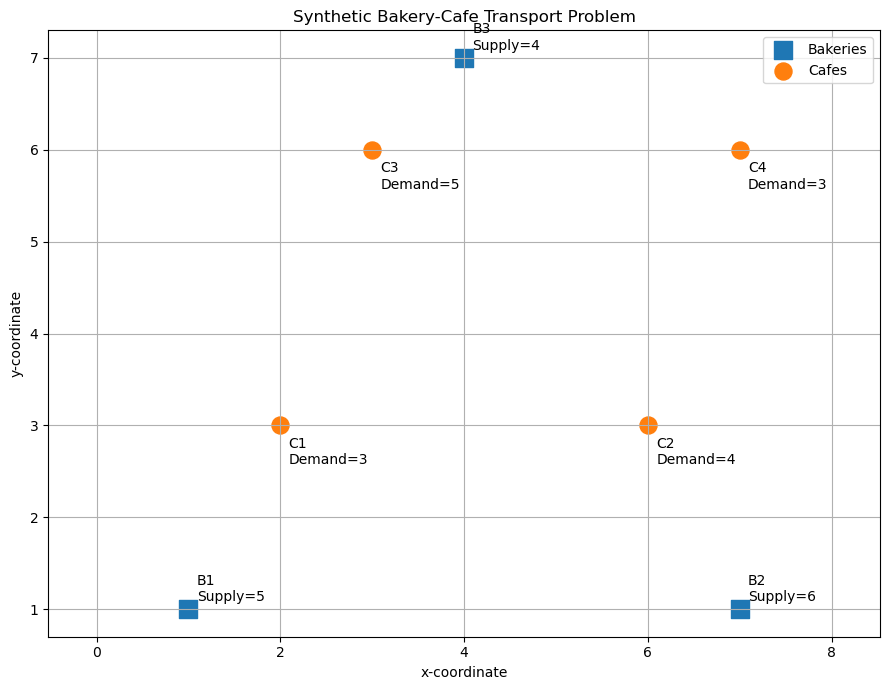


FINAL VERIFICATION
PASS: The synthetic city defines a valid balanced transport problem.


In [1]:
# ============================================================
# HOMEWORK 3.1 - PART I
# GENERATE AND VERIFY A DISCRETE TRANSPORT PROBLEM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# BAKERY DATA
# ============================================================

bakery_locations = np.array([
    [1.0, 1.0],
    [7.0, 1.0],
    [4.0, 7.0]
])

bakery_supply = np.array([
    5.0,
    6.0,
    4.0
])


# ============================================================
# CAFE DATA
# ============================================================

cafe_locations = np.array([
    [2.0, 3.0],
    [6.0, 3.0],
    [3.0, 6.0],
    [7.0, 6.0]
])

cafe_demand = np.array([
    3.0,
    4.0,
    5.0,
    3.0
])


# ============================================================
# BASIC DIMENSIONS
# ============================================================

N = len(bakery_locations)

M = len(cafe_locations)


print("=" * 65)
print("DISCRETE TRANSPORT PROBLEM")
print("=" * 65)

print(
    "Number of bakeries N =",
    N
)

print(
    "Number of cafes M =",
    M
)


# ============================================================
# SUPPLY AND DEMAND CHECKS
# ============================================================

total_supply = np.sum(
    bakery_supply
)

total_demand = np.sum(
    cafe_demand
)


print()

print("SUPPLY AND DEMAND")
print("-" * 65)

print(
    "Bakery supplies =",
    bakery_supply
)

print(
    "Cafe demands =",
    cafe_demand
)

print(
    "Total supply =",
    total_supply
)

print(
    "Total demand =",
    total_demand
)


# ============================================================
# AUTOMATIC VALIDITY CHECKS
# ============================================================

assert np.all(
    bakery_supply > 0
), "All bakery supplies must be positive."


assert np.all(
    cafe_demand > 0
), "All cafe demands must be positive."


assert np.isclose(
    total_supply,
    total_demand
), "Total supply must equal total demand."


assert bakery_locations.shape == (
    N,
    2
)


assert cafe_locations.shape == (
    M,
    2
)


print()

print(
    "PASS: All supplies are positive."
)

print(
    "PASS: All demands are positive."
)

print(
    "PASS: Total supply equals total demand."
)

print(
    "PASS: All locations are points in R^2."
)


# ============================================================
# COMPUTE EUCLIDEAN COST MATRIX
#
# C_ij = ||x_i - y_j||
# ============================================================

difference = (

    bakery_locations[:, None, :]

    -

    cafe_locations[None, :, :]
)


euclidean_cost = np.sqrt(

    np.sum(
        difference**2,
        axis=2
    )

)


# ============================================================
# COMPUTE SQUARED EUCLIDEAN COST MATRIX
#
# C2_ij = ||x_i - y_j||^2
# ============================================================

squared_cost = np.sum(
    difference**2,
    axis=2
)


# ============================================================
# PRINT COST MATRICES
# ============================================================

print()

print("=" * 65)

print(
    "EUCLIDEAN COST MATRIX"
)

print("=" * 65)

print(
    np.round(
        euclidean_cost,
        4
    )
)


print()

print("=" * 65)

print(
    "SQUARED EUCLIDEAN COST MATRIX"
)

print("=" * 65)

print(
    squared_cost
)


# ============================================================
# VERIFY SQUARED COST
# ============================================================

assert np.allclose(

    squared_cost,

    euclidean_cost**2

)


print()

print(
    "PASS: Squared Euclidean costs equal "
    "the square of Euclidean costs."
)


# ============================================================
# CREATE READABLE TABLES
# ============================================================

bakery_names = [
    "Bakery 1",
    "Bakery 2",
    "Bakery 3"
]


cafe_names = [
    "Cafe 1",
    "Cafe 2",
    "Cafe 3",
    "Cafe 4"
]


euclidean_df = pd.DataFrame(

    euclidean_cost,

    index=bakery_names,

    columns=cafe_names
)


squared_df = pd.DataFrame(

    squared_cost,

    index=bakery_names,

    columns=cafe_names
)


print()

print(
    "EUCLIDEAN COST TABLE"
)

print("-" * 65)

print()

print(
    euclidean_df.round(4)
)


print()

print(
    "SQUARED EUCLIDEAN COST TABLE"
)

print("-" * 65)

print()

print(
    squared_df
)


# ============================================================
# MANUAL CHECK OF ONE ENTRY
#
# Bakery 1 = (1,1)
# Cafe 1   = (2,3)
#
# Distance = sqrt(5)
# ============================================================

manual_c11 = np.sqrt(
    (1 - 2)**2
    +
    (1 - 3)**2
)


print()

print("=" * 65)

print(
    "MANUAL DISTANCE CHECK"
)

print("=" * 65)

print(
    "Calculated c_11 =",
    euclidean_cost[0, 0]
)

print(
    "Manual sqrt(5) =",
    manual_c11
)


assert np.isclose(
    euclidean_cost[0, 0],
    manual_c11
)


print()

print(
    "PASS: Manual distance calculation "
    "matches the cost matrix."
)


# ============================================================
# PLOT THE SYNTHETIC CITY
# ============================================================

plt.figure(
    figsize=(9, 7)
)


# Bakeries
plt.scatter(

    bakery_locations[:, 0],

    bakery_locations[:, 1],

    s=150,

    marker="s",

    label="Bakeries"
)


# Cafes
plt.scatter(

    cafe_locations[:, 0],

    cafe_locations[:, 1],

    s=150,

    marker="o",

    label="Cafes"
)


# Bakery labels
for i, (x, y) in enumerate(
    bakery_locations
):

    plt.annotate(

        f"B{i+1}\nSupply={bakery_supply[i]:.0f}",

        (x, y),

        xytext=(6, 6),

        textcoords="offset points"
    )


# Cafe labels
for j, (x, y) in enumerate(
    cafe_locations
):

    plt.annotate(

        f"C{j+1}\nDemand={cafe_demand[j]:.0f}",

        (x, y),

        xytext=(6, -28),

        textcoords="offset points"
    )


plt.xlabel(
    "x-coordinate"
)

plt.ylabel(
    "y-coordinate"
)

plt.title(
    "Synthetic Bakery-Cafe Transport Problem"
)

plt.grid(
    True
)

plt.legend()

plt.axis(
    "equal"
)

plt.tight_layout()


plt.savefig(
    "bakery_cafe_synthetic_city.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL CHECK
# ============================================================

print()

print("=" * 65)

print(
    "FINAL VERIFICATION"
)

print("=" * 65)


if (
    np.all(bakery_supply > 0)
    and
    np.all(cafe_demand > 0)
    and
    np.isclose(
        total_supply,
        total_demand
    )
):

    print(
        "PASS: The synthetic city defines "
        "a valid balanced transport problem."
    )